# 05 — Predicting Late Deliveries

**Question:** at the moment a PO line is raised, can we predict whether it will arrive late, so buyers can expedite,
add buffer or choose another vendor *before* it becomes a problem?

**Set-up**
- **Target:** `late` = the first receipt arrived after the promised date. Lines overdue and not yet received count as late.
  Only lines due by the data cut-off are used.
- **Features known at order time only.** No information from the future leaks in:
  - order details: order type, category, quantity, value, promised lead time;
  - calendar: monsoon month, and whether the vendor is in a monsoon-hit state;
  - **vendor track record up to the order date:** late rate and average delay over all earlier lines, and the late rate over
    the last 180 days. Only lines whose promised date had *already passed* when the order was placed are counted, because
    only their outcome was known at that point.
- **Time-based split:** train on orders from 2023–2024, test on orders from 2025. This mimics using the model going forward;
  a random split would let the model peek at the future.
- **Models:**
  - a baseline: the vendor's past late rate alone;
  - logistic regression;
  - a random forest.

In [1]:
import sys
sys.path.append("../src")

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sqlalchemy import text

from db import get_engine
from utils import REPORTS_DIR
from viz_style import INK_2, MUTED, SERIES, apply_style, save, subtitle

apply_style()
engine = get_engine()
RISK_DIR = REPORTS_DIR / "risk"
RISK_DIR.mkdir(exist_ok=True)


def q(sql, dates=()):
    df = pd.read_sql(text(sql), engine)
    for c in dates:
        df[c] = pd.to_datetime(df[c])
    return df


pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Data and features

In [2]:
L = q('''
SELECT po_id, line_no, order_date, promised_date, order_type, vendor_id, vendor_state, category,
       quantity, line_value, is_due, is_on_time, delay_days, first_received
FROM v_po_lines
''', dates=["order_date", "promised_date", "first_received"])
L["line_value"] = L.line_value.astype(float)
L["late"] = 1 - L.is_on_time
L = L.reset_index(drop=True)

# Monsoon-hit states, as found in the EDA (late rate +14-17 pp in June-September)
MONSOON_STATES = ["Assam", "Kerala", "Maharashtra", "West Bengal"]
L["promised_lead_days"] = (L.promised_date - L.order_date).dt.days
L["log_quantity"] = np.log1p(L.quantity)
L["log_value"] = np.log(L.line_value)
L["monsoon_month"] = L.promised_date.dt.month.between(6, 9).astype(int)
L["monsoon_state"] = L.vendor_state.isin(MONSOON_STATES).astype(int)
L["monsoon_state_x_month"] = L.monsoon_month * L.monsoon_state
print(f"{len(L):,} PO lines; {L.is_due.sum():,} due by the cut-off; late rate among due lines {L[L.is_due == 1].late.mean():.1%}")

49,971 PO lines; 49,310 due by the cut-off; late rate among due lines 29.0%


In [3]:
def vendor_history(lines, window_days=None):
    '''For every line: the vendor's late rate, number of known outcomes and average delay of late lines,
    using only lines of the same vendor whose promised date was before this line's order date.'''
    known = lines[lines.is_due == 1].sort_values("promised_date")
    rate = np.full(len(lines), np.nan)
    count = np.zeros(len(lines))
    delay = np.full(len(lines), np.nan)
    for vendor, idx in lines.groupby("vendor_id").groups.items():
        h = known[known.vendor_id == vendor]
        t = h.promised_date.to_numpy()
        late_cum = np.concatenate([[0], np.cumsum(h.late.to_numpy())])
        late_delay = np.where(h.late.to_numpy() == 1, h.delay_days.fillna(0).to_numpy(), 0)
        delay_cum = np.concatenate([[0], np.cumsum(late_delay)])
        order_dates = lines.loc[idx, "order_date"].to_numpy()
        hi = np.searchsorted(t, order_dates, side="left")
        lo = (np.searchsorted(t, order_dates - np.timedelta64(window_days, "D"), side="left")
              if window_days else np.zeros_like(hi))
        n = hi - lo
        n_late = late_cum[hi] - late_cum[lo]
        pos = lines.index.get_indexer(idx)
        count[pos] = n
        with np.errstate(invalid="ignore", divide="ignore"):
            rate[pos] = np.where(n > 0, n_late / n, np.nan)
            delay[pos] = np.where(n_late > 0, (delay_cum[hi] - delay_cum[lo]) / n_late, np.nan)
    return rate, count, delay


L["vendor_past_late_rate"], L["vendor_past_lines"], L["vendor_past_avg_delay"] = vendor_history(L)
L["vendor_recent_late_rate"], _, _ = vendor_history(L, window_days=180)
L["log_vendor_past_lines"] = np.log1p(L.vendor_past_lines)
L[["vendor_past_late_rate", "vendor_past_lines", "vendor_past_avg_delay", "vendor_recent_late_rate"]].describe().T

,count,mean,std,min,25%,50%,75%,max
vendor_past_late_rate,"49,218.000",0.286,0.137,0.000,0.196,0.263,0.398,1.000
vendor_past_lines,"49,971.000",582.875,721.644,0.000,84.000,271.000,805.000,"3,381.000"
vendor_past_avg_delay,"48,446.000",8.927,5.267,1.000,4.552,7.200,11.794,30.000
vendor_recent_late_rate,"49,214.000",0.291,0.146,0.000,0.189,0.278,0.404,1.000


## 2. Train / test split (by time)

In [4]:
NUMERIC = ["promised_lead_days", "log_quantity", "log_value", "monsoon_month", "monsoon_state", "monsoon_state_x_month",
           "vendor_past_late_rate", "vendor_recent_late_rate", "vendor_past_avg_delay", "log_vendor_past_lines"]
CATEGORICAL = ["order_type", "category"]
FEATURES = NUMERIC + CATEGORICAL

due = L[L.is_due == 1].copy()
train = due[due.order_date < "2025-01-01"].copy()
test = due[due.order_date >= "2025-01-01"].copy()

# Vendors with no history yet: fall back to the overall late rate seen in training
fill = {"vendor_past_late_rate": train.late.mean(), "vendor_recent_late_rate": train.late.mean(),
        "vendor_past_avg_delay": train.loc[train.late == 1, "delay_days"].mean()}
for df in (train, test, L):
    df.fillna(fill, inplace=True)

print(f"Train: {len(train):,} lines (orders 2023–2024), late rate {train.late.mean():.1%}")
print(f"Test:  {len(test):,} lines (orders 2025), late rate {test.late.mean():.1%}")

Train: 31,714 lines (orders 2023–2024), late rate 29.0%
Test:  17,596 lines (orders 2025), late rate 29.1%


## 3. Models

In [5]:
pre = ColumnTransformer([("num", StandardScaler(), NUMERIC),
                         ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL)])
models = {
    "Logistic regression": make_pipeline(pre, LogisticRegression(max_iter=2000)),
    "Random forest": make_pipeline(pre, RandomForestClassifier(n_estimators=400, min_samples_leaf=30, max_features=0.5,
                                                                n_jobs=-1, random_state=42)),
}
scores = {"Baseline: vendor's past late rate": test.vendor_past_late_rate.to_numpy()}
for name, m in models.items():
    m.fit(train[FEATURES], train.late)
    scores[name] = m.predict_proba(test[FEATURES])[:, 1]


def evaluate(y, s, top=0.2):
    cut = np.quantile(s, 1 - top)
    flagged = s >= cut
    return {"ROC-AUC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s),
            "late lines caught in riskiest 20%": y[flagged].sum() / y.sum(),
            "precision in riskiest 20%": y[flagged].mean()}


y = test.late.to_numpy()
results = pd.DataFrame({name: evaluate(y, s) for name, s in scores.items()}).T
results["base late rate"] = y.mean()
results

,ROC-AUC,PR-AUC,late lines caught in riskiest 20%,precision in riskiest 20%,base late rate
Baseline: vendor's past late rate,0.659,0.417,0.321,0.467,0.291
Logistic regression,0.674,0.441,0.326,0.474,0.291
Random forest,0.671,0.432,0.319,0.464,0.291


### How good could any model be? (simulation check)

Each late delivery in this synthetic data was drawn at random from a true probability. That probability depends on the
vendor's reliability, order type, monsoon exposure and 2025 decline (`data/truth/vendor_traits.csv`). Even a model that knew
those probabilities exactly could not reach AUC 1.0. Scoring the test lines with the **true** probabilities gives the
best AUC any model could achieve here. The model never sees these values; they serve only as a ruler.

In [6]:
from utils import ROOT

traits = pd.read_csv(ROOT / "data" / "truth" / "vendor_traits.csv").set_index("vendor_id")
t = test.join(traits[["on_time_prob", "monsoon_exposed", "declining_2025"]], on="vendor_id")
true_p = (1 - t.on_time_prob + 0.10 * (t.order_type == "Urgent") + 0.05 * (t.order_type == "Bulk")
          + 0.15 * (t.monsoon_exposed & t.promised_date.dt.month.between(6, 9))
          + 0.25 * (t.declining_2025 & (t.order_date.dt.year == 2025))).clip(upper=0.95)
ceiling = roc_auc_score(y, true_p)
best = results["ROC-AUC"].max()
print(f"Best achievable ROC-AUC (true probabilities): {ceiling:.3f}")
print(f"Best model: {best:.3f} -> {(best - 0.5) / (ceiling - 0.5):.0%} of the achievable gain over random guessing")

Best achievable ROC-AUC (true probabilities): 0.690
Best model: 0.674 -> 92% of the achievable gain over random guessing


**How to read this**
- **ROC-AUC:** the chance that a randomly picked late line is scored riskier than a randomly picked on-time line. 0.5 is a coin
  flip; 1.0 is perfect.
- **PR-AUC:** compare it with the base late rate. A random model's PR-AUC equals the base rate.
- **Riskiest 20%:** if buyers reviewed only the 20% of new lines the model scores riskiest, this is the share of all late lines
  they would catch, and how often a flagged line really turns out late.

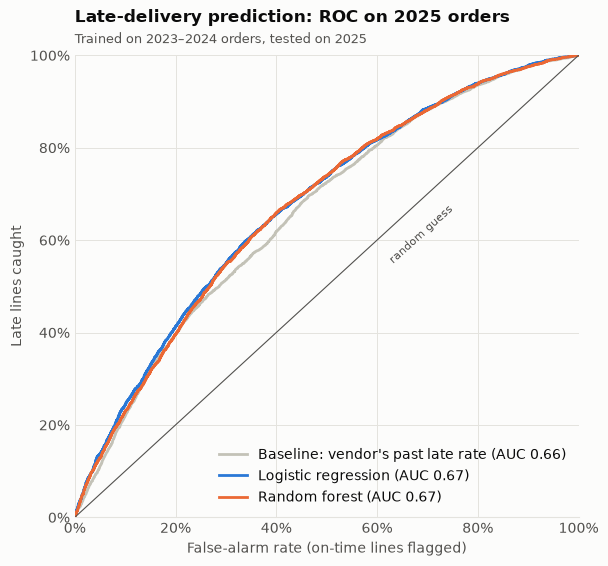

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for (name, s), color in zip(scores.items(), [MUTED, SERIES[0], SERIES[1]]):
    fpr, tpr, _ = roc_curve(y, s)
    ax.plot(fpr, tpr, color=color, label=f"{name} (AUC {roc_auc_score(y, s):.2f})")
ax.plot([0, 1], [0, 1], color=INK_2, lw=0.8)
ax.text(0.62, 0.55, "random guess", color=INK_2, fontsize=8, rotation=42)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="False-alarm rate (on-time lines flagged)", ylabel="Late lines caught")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.legend(loc="lower right")
ax.set_title("Late-delivery prediction: ROC on 2025 orders")
subtitle(ax, "Trained on 2023–2024 orders, tested on 2025")
save(fig, "21_delay_model_roc")

risk_decile,1,2,3,4,5,6,7,8,9,10
late %,9.261,15.398,21.205,22.500,25.412,28.409,34.565,39.602,43.434,51.364


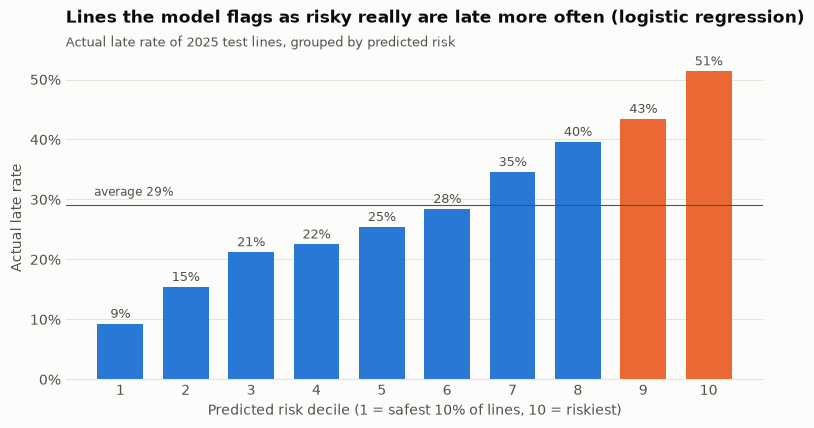

In [8]:
best_name = results["ROC-AUC"].idxmax()
test["risk"] = scores[best_name]
test["risk_decile"] = pd.qcut(test.risk.rank(method="first"), 10, labels=range(1, 11)).astype(int)
dec = test.groupby("risk_decile").late.mean() * 100

fig, ax = plt.subplots()
ax.bar(dec.index.astype(str), dec, color=[SERIES[1] if d >= 9 else SERIES[0] for d in dec.index], width=0.7)
for x, v in enumerate(dec):
    ax.text(x, v + 1, f"{v:.0f}%", ha="center", color=INK_2, fontsize=9)
ax.axhline(y.mean() * 100, color=INK_2, lw=0.8)
ax.text(-0.4, y.mean() * 100 + 1.5, f"average {y.mean():.0%}", color=INK_2, fontsize=8.5)
ax.set_xlabel("Predicted risk decile (1 = safest 10% of lines, 10 = riskiest)")
ax.set_ylabel("Actual late rate")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(axis="x", visible=False)
ax.set_title(f"Lines the model flags as risky really are late more often ({best_name.lower()})")
subtitle(ax, "Actual late rate of 2025 test lines, grouped by predicted risk")
save(fig, "22_delay_model_deciles")
dec.rename("late %").to_frame().T

## 4. What drives the prediction?

,AUC drop
vendor_past_late_rate,0.061
monsoon_state_x_month,0.011
order_type,0.009
vendor_recent_late_rate,0.006
vendor_past_avg_delay,0.006
log_vendor_past_lines,0.001
promised_lead_days,0.001
monsoon_month,0.001
log_value,0.000
log_quantity,0.000


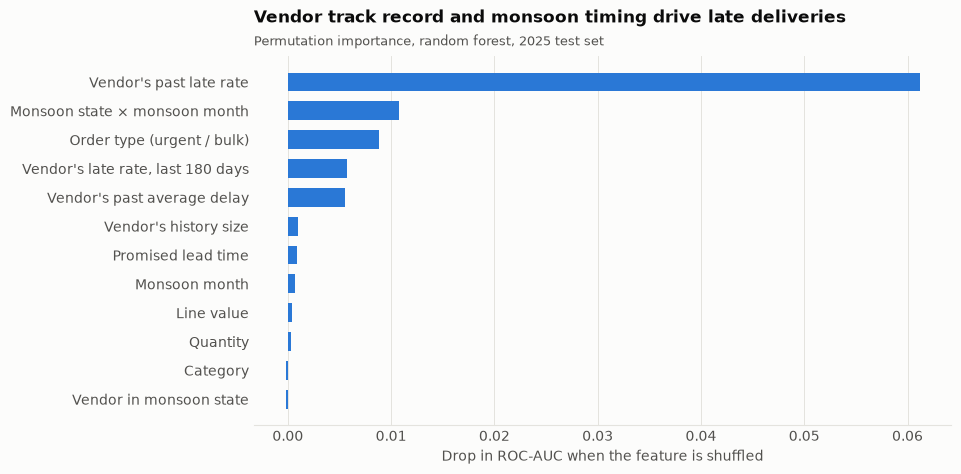

In [9]:
rf = models["Random forest"]
imp = permutation_importance(rf, test[FEATURES], test.late, scoring="roc_auc", n_repeats=5, random_state=42)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
labels = {"vendor_past_late_rate": "Vendor's past late rate", "vendor_recent_late_rate": "Vendor's late rate, last 180 days",
          "vendor_past_avg_delay": "Vendor's past average delay", "log_vendor_past_lines": "Vendor's history size",
          "monsoon_state_x_month": "Monsoon state × monsoon month", "monsoon_month": "Monsoon month",
          "monsoon_state": "Vendor in monsoon state", "order_type": "Order type (urgent / bulk)",
          "promised_lead_days": "Promised lead time", "category": "Category", "log_quantity": "Quantity",
          "log_value": "Line value"}

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(importance.index.map(labels), importance, color=SERIES[0], height=0.65)
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
ax.grid(axis="y", visible=False)
ax.set_title("Vendor track record and monsoon timing drive late deliveries")
subtitle(ax, "Permutation importance, random forest, 2025 test set")
save(fig, "23_delay_model_importance")
importance.sort_values(ascending=False).rename("AUC drop").to_frame()

In [10]:
lr = models["Logistic regression"].named_steps["logisticregression"]
names = models["Logistic regression"].named_steps["columntransformer"].get_feature_names_out()
coef = pd.Series(lr.coef_[0], index=[n.split("__")[1] for n in names]).sort_values()
pd.DataFrame({"coefficient": coef, "odds ratio per unit": np.exp(coef)}).loc[coef.abs().sort_values(ascending=False).index].head(10)

,coefficient,odds ratio per unit
order_type_Regular,-0.491,0.612
vendor_past_late_rate,0.457,1.580
monsoon_state_x_month,0.203,1.225
category_Office Supplies,-0.196,0.822
order_type_Bulk,-0.140,0.869
vendor_past_avg_delay,0.123,1.131
category_MRO,-0.122,0.885
order_type_Urgent,0.104,1.110
monsoon_state,-0.089,0.915
category_IT Hardware,-0.088,0.915


Logistic-regression coefficients point the same way as the forest: a worse vendor record, urgent orders and monsoon timing
raise the odds of a late delivery. Numeric features are standardised, so their coefficients compare per standard deviation.

## 5. Score the lines not yet due

The model is refit on **all** due lines, then scores PO lines whose promised date falls after the cut-off. This is the
early-warning list: the open orders most likely to arrive late, for buyers to chase now.

In [11]:
final = make_pipeline(pre, RandomForestClassifier(n_estimators=400, min_samples_leaf=30, max_features=0.5,
                                                   n_jobs=-1, random_state=42))
final.fit(due[FEATURES], due.late)
upcoming = L[L.is_due == 0].copy()
upcoming["late_probability"] = final.predict_proba(upcoming[FEATURES])[:, 1]
upcoming["risk_band"] = pd.cut(upcoming.late_probability, [0, 0.3, 0.5, 1], labels=["Low", "Medium", "High"])
cols = ["po_id", "line_no", "vendor_id", "category", "order_type", "order_date", "promised_date", "line_value",
        "late_probability", "risk_band"]
watch = upcoming.sort_values("late_probability", ascending=False)[cols]
watch.to_sql("po_line_late_risk", engine, if_exists="replace", index=False)
watch.to_csv(RISK_DIR / "upcoming_po_late_risk.csv", index=False)
results.to_csv(RISK_DIR / "delay_model_results.csv")
print(f"{len(upcoming):,} lines not yet due scored; High risk (≥ 50%): {(upcoming.risk_band == 'High').sum()} lines, "
      f"₹{upcoming.loc[upcoming.risk_band == 'High', 'line_value'].sum() / 1e7:,.1f} cr")
print("Saved to procurement_db.po_line_late_risk and reports/risk/upcoming_po_late_risk.csv")
watch.head(10)

661 lines not yet due scored; High risk (≥ 50%): 28 lines, ₹1.3 cr
Saved to procurement_db.po_line_late_risk and reports/risk/upcoming_po_late_risk.csv


,po_id,line_no,vendor_id,category,order_type,order_date,promised_date,line_value,late_probability,risk_band
34087,PO022725,1,V102,MRO,Urgent,2025-12-31,2026-01-02,"41,711.840",0.637,High
8359,PO022672,1,V011,Raw Materials,Regular,2025-12-30,2026-01-15,"1,020,358.060",0.585,High
977,PO022410,4,V011,Raw Materials,Regular,2025-12-19,2026-01-04,"1,231,164.690",0.584,High
9794,PO022410,3,V011,Raw Materials,Regular,2025-12-19,2026-01-01,"654,691.860",0.574,High
2734,PO022410,2,V011,Raw Materials,Regular,2025-12-19,2026-01-03,"415,198.000",0.574,High
3335,PO022410,5,V011,Raw Materials,Regular,2025-12-19,2026-01-01,"545,973.680",0.570,High
4585,PO022410,1,V011,Raw Materials,Regular,2025-12-19,2026-01-03,"142,205.820",0.559,High
40772,PO022443,2,V106,IT Hardware,Bulk,2025-12-22,2026-01-11,"829,917.880",0.558,High
39217,PO022443,3,V106,IT Hardware,Bulk,2025-12-22,2026-01-10,"646,418.110",0.555,High
7328,PO022455,4,V010,Raw Materials,Regular,2025-12-22,2026-01-07,"447,664.640",0.535,High


## 6. Summary

Full write-up: [`reports/risk_report.md`](../reports/risk_report.md).

- The logistic regression reaches **ROC-AUC 0.674**, against 0.659 for the vendor-history baseline. The best achievable on this data is 0.690, so the model captures 92% of the achievable gain.
- The riskiest decile of lines is late 51% of the time, against 9% for the safest decile.
- The vendor's track record dominates the prediction; monsoon timing and order type add to it.
- 661 lines not yet due were scored; 28 are High risk. They are stored in `po_line_late_risk` for buyers to chase.